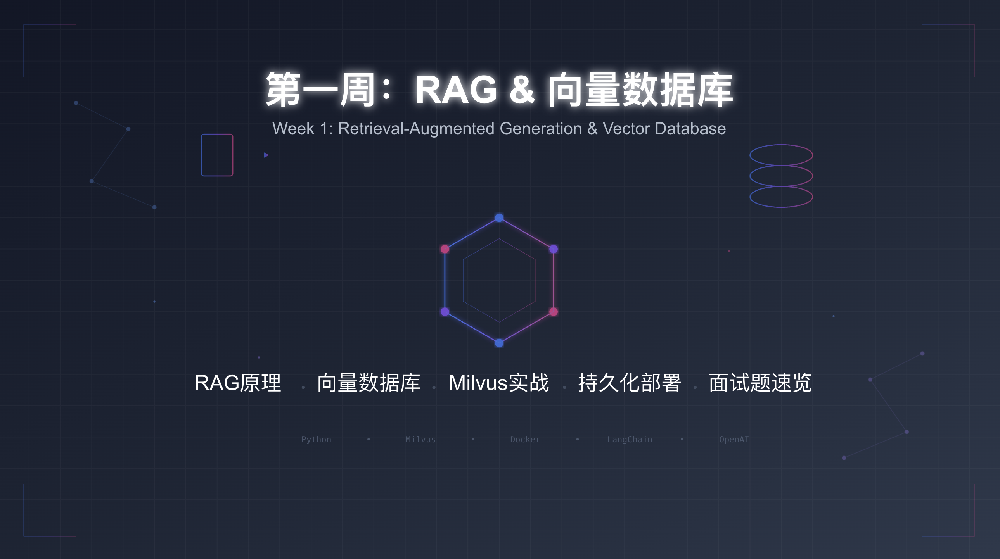

# 0. 开发人员如何调用大模型API

这是日常我们和LLM的交互
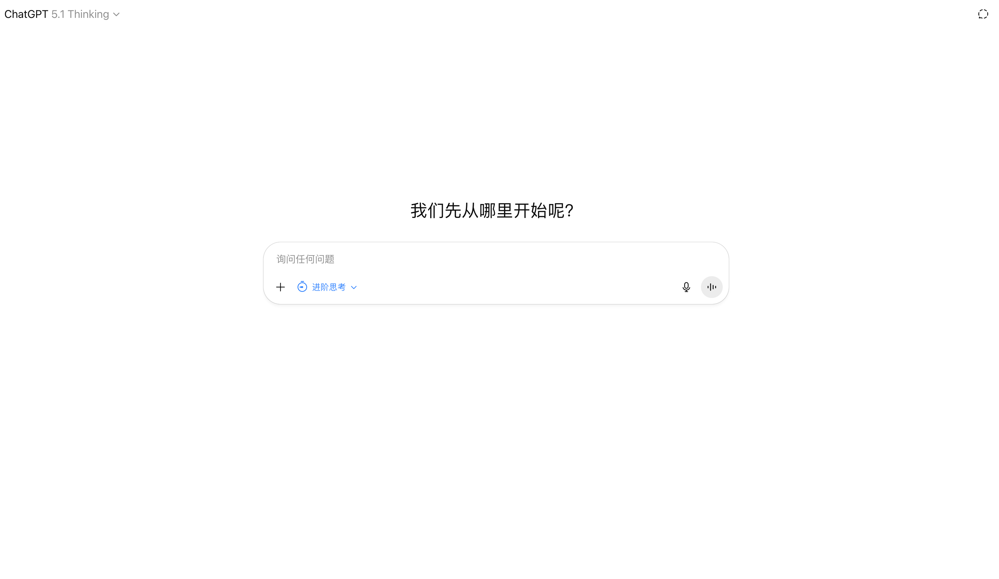

### 阿里云百炼
https://bailian.console.aliyun.com/?spm=5176.29619931.nav-v2-dropdown-menu-0.d_main_2_0_0.724d70e8xBOirD&tab=api&scm=20140722.M_10904466._.V_1#/api/?type=model&url=2712576

In [ ]:
# 掌握以下3中API的调用方式，足矣

## 0.1 非流式输出

In [15]:
# 非流式输出

import os
from openai import OpenAI
from dotenv import load_dotenv

# 加载 .env 文件中的环境变量
load_dotenv()

def qwen_qa(prompt):
    client = OpenAI(
        # 若没有配置环境变量，请用百炼API Key将下行替换为：api_key="sk-xxx"
        api_key=os.getenv("DASHSCOPE_API_KEY"),
        base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    )
    
    completion = client.chat.completions.create(
        # 模型列表：https://help.aliyun.com/zh/model-studio/getting-started/models
        model="qwen-plus",
        messages=[
            {"role": "system", "content": "You are a helpful assistant."},
            {"role": "user", "content": prompt},
        ]
    )
return completion.model_dump_json()

{"id":"chatcmpl-4907713f-b1e8-4232-874f-c5f5d7e1ce37","choices":[{"finish_reason":"stop","index":0,"logprobs":null,"message":{"content":"我是通义千问，阿里巴巴集团旗下的超大规模语言模型。我能够回答问题、创作文字，如写故事、公文、邮件、剧本等，还能进行逻辑推理、编程，表达观点，玩游戏等。你可以叫我Qwen，我将尽力为你提供帮助。","refusal":null,"role":"assistant","annotations":null,"audio":null,"function_call":null,"tool_calls":null}}],"created":1763297721,"model":"qwen-plus","object":"chat.completion","service_tier":null,"system_fingerprint":null,"usage":{"completion_tokens":59,"prompt_tokens":22,"total_tokens":81,"completion_tokens_details":null,"prompt_tokens_details":{"audio_tokens":null,"cached_tokens":0}}}


In [16]:
print(completion.choices[0].message.content)

我是通义千问，阿里巴巴集团旗下的超大规模语言模型。我能够回答问题、创作文字，如写故事、公文、邮件、剧本等，还能进行逻辑推理、编程，表达观点，玩游戏等。你可以叫我Qwen，我将尽力为你提供帮助。


## 0.2 流式输出

In [17]:
# 流式输出

import os
from openai import OpenAI
from dotenv import load_dotenv

# 加载 .env 文件中的环境变量
load_dotenv()

client = OpenAI(
    # 若没有配置环境变量，请用百炼API Key将下行替换为：api_key="sk-xxx"
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)
completion = client.chat.completions.create(
    model="qwen-plus",  # 此处以qwen-plus为例，可按需更换模型名称。模型列表：https://help.aliyun.com/zh/model-studio/getting-started/models
    messages=[{'role': 'system', 'content': 'You are a helpful assistant.'},
                {'role': 'user', 'content': '你是谁？'}],
    stream=True,
    stream_options={"include_usage": True}
    )
# 流式输出，只打印文本内容
for chunk in completion:
    # 检查是否有内容
    if chunk.choices and len(chunk.choices) > 0:
        # 获取增量内容
        delta_content = chunk.choices[0].delta.content
        if delta_content:
            # 直接打印文本，不换行
            print(delta_content, end='', flush=True)

# 打印换行符结束输出
print()

我是通义千问，是阿里巴巴集团旗下的通义实验室自主研发的超大规模语言模型。我可以帮助你回答问题、创作文字、进行逻辑推理、编程等任务。如果你有任何需要帮助的地方，欢迎随时告诉我！


In [18]:
import os
from openai import OpenAI

# 1. 准备工作：初始化客户端
client = OpenAI(
    # 建议通过环境变量配置API Key，避免硬编码。
    api_key=os.environ["DASHSCOPE_API_KEY"],
    # API Key与地域强绑定，请确保base_url与API Key的地域一致。
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)

# 2. 发起流式请求
completion = client.chat.completions.create(
    model="qwen-plus",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "请介绍一下自己"}
    ],
    stream=True,
    stream_options={"include_usage": True}
)

# 3. 处理流式响应
# 用列表暂存响应片段，最后 join 比逐次 += 字符串更高效
content_parts = []
print("AI: ", end="", flush=True)

for chunk in completion:
    if chunk.choices:
        content = chunk.choices[0].delta.content or ""
        print(content, end="", flush=True)
        content_parts.append(content)
    elif chunk.usage:
        print("\n--- 请求用量 ---")
        print(f"输入 Tokens: {chunk.usage.prompt_tokens}")
        print(f"输出 Tokens: {chunk.usage.completion_tokens}")
        print(f"总计 Tokens: {chunk.usage.total_tokens}")

full_response = "".join(content_parts)
# print(f"\n--- 完整回复 ---\n{full_response}")

AI: 你好！我是Qwen，是阿里巴巴集团旗下的通义实验室自主研发的一款超大规模语言模型。我的中文名字叫通义千问，英文名字叫Qwen。我能够回答问题、创作文字，比如写故事、写公文、写邮件、写剧本、逻辑推理、编程等等，还能表达观点，玩游戏等。

如果你有任何问题或需要帮助，尽管告诉我，我会尽力提供支持！
--- 请求用量 ---
输入 Tokens: 22
输出 Tokens: 85
总计 Tokens: 107


## 0.3 多轮对话

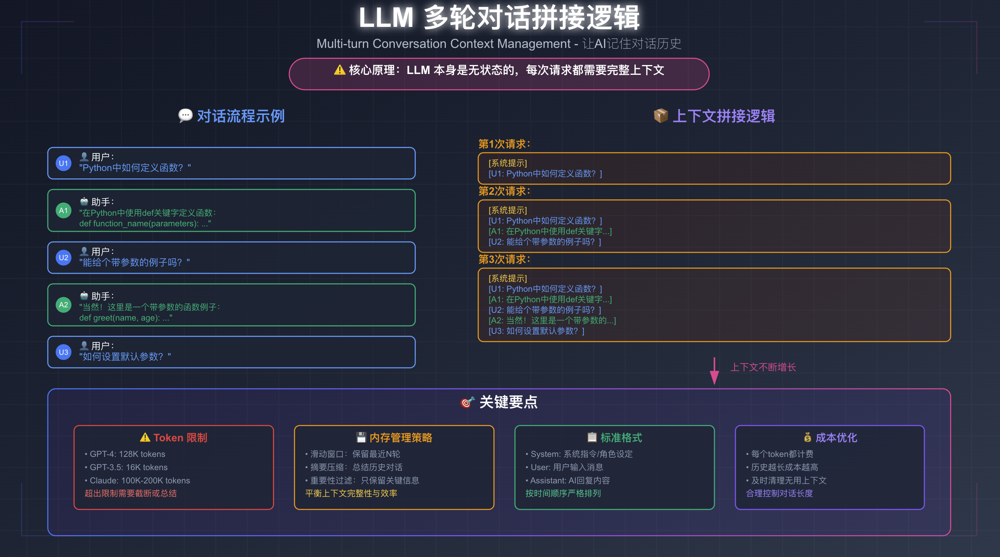

# 求职技能四件套：RAG，Agent，SFT，RL

# 1. RAG

## 1.1 为什么要做RAG

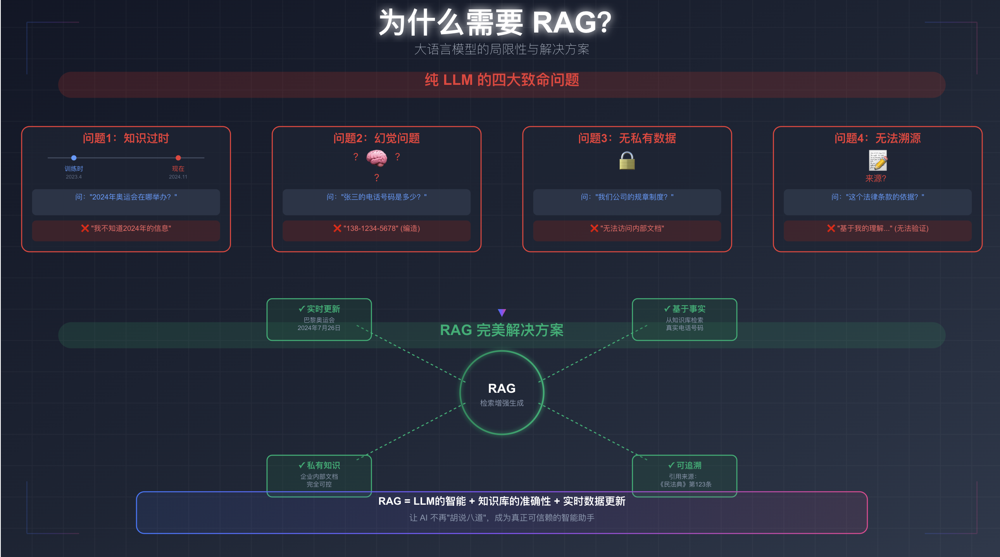

**也因此，你所有的项目背景一定是从这四个需求出发**

## 1.2 什么是RAG

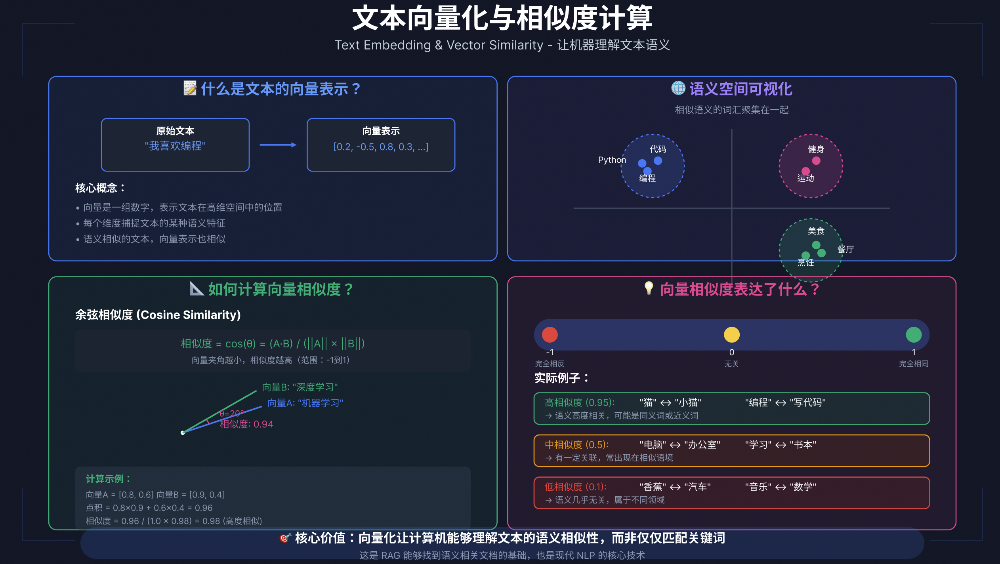

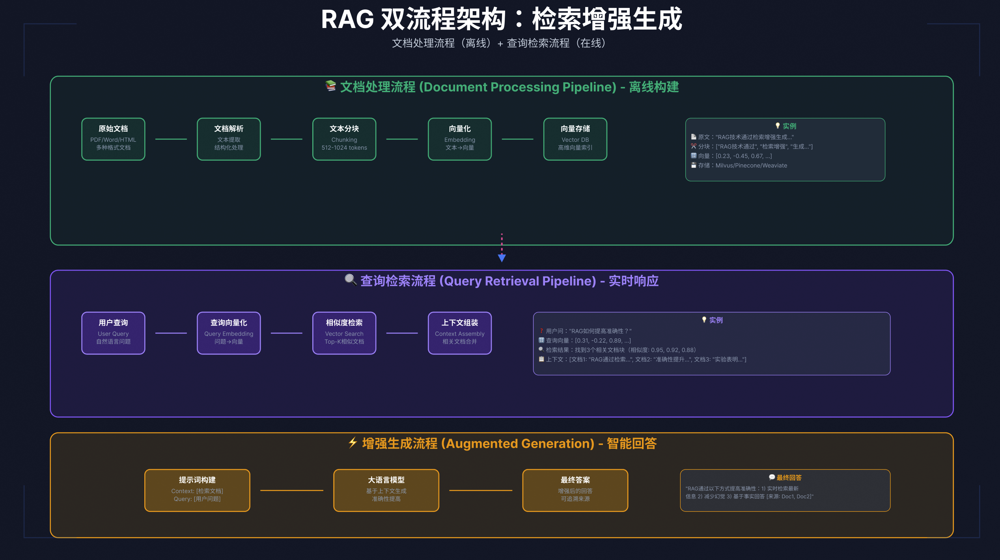

# 2. 从向量数据库开始

## 2.1 向量数据库核心概念

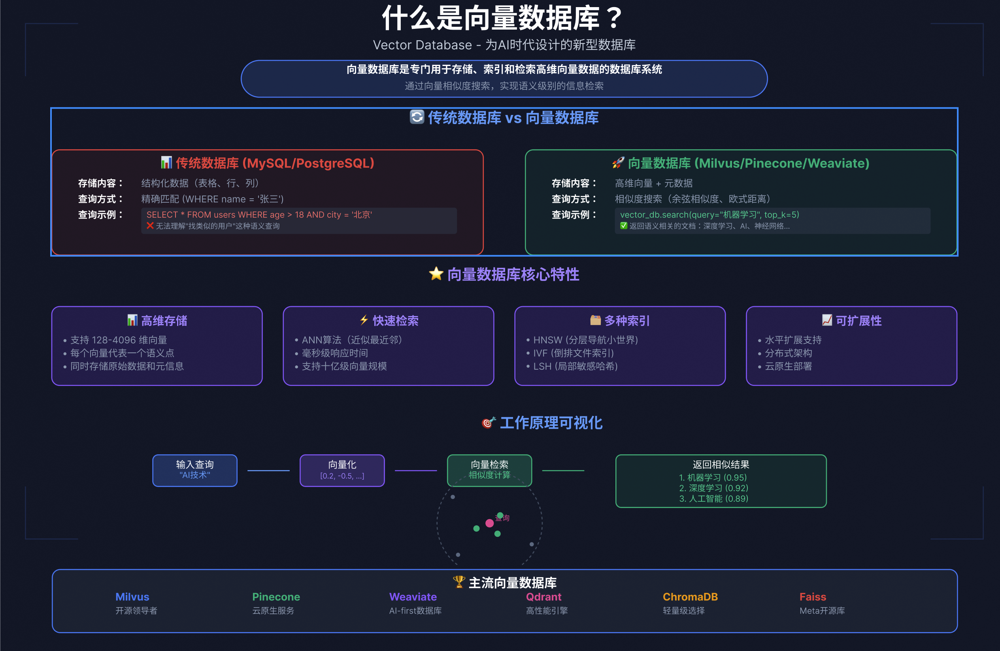

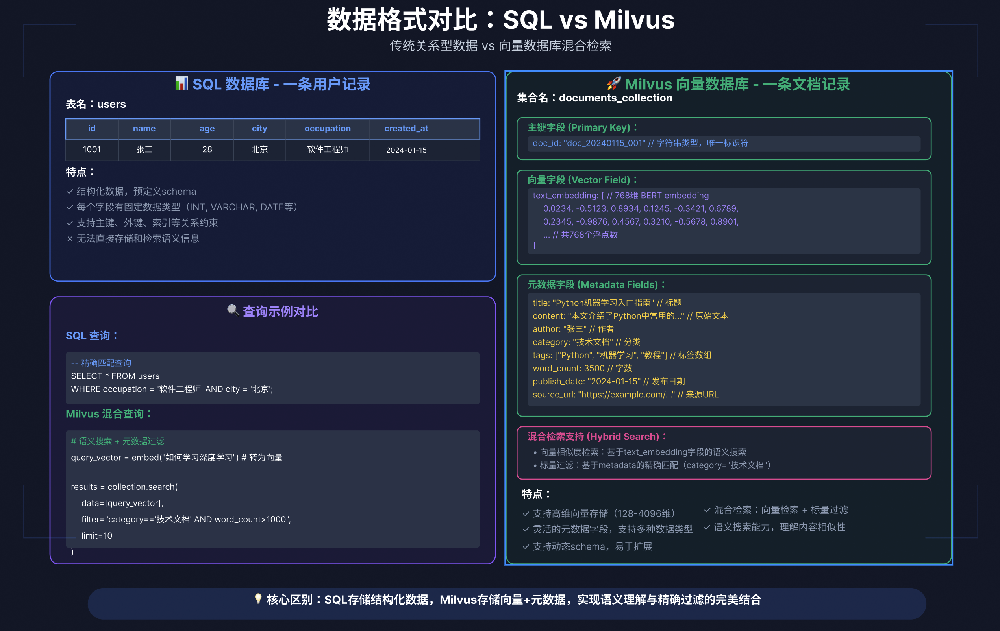

### 我们来看一下具体的数据库里面的格式长什么样子

https://acnfgkjh8azx.feishu.cn/docx/Z2ILdAMR3odQnXxMraVc6WBJnne

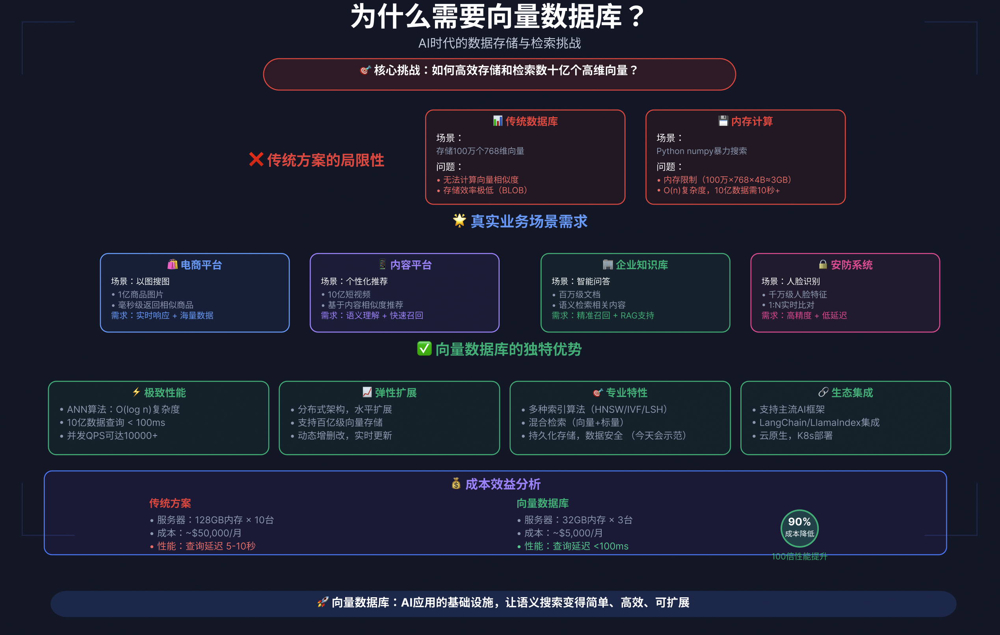

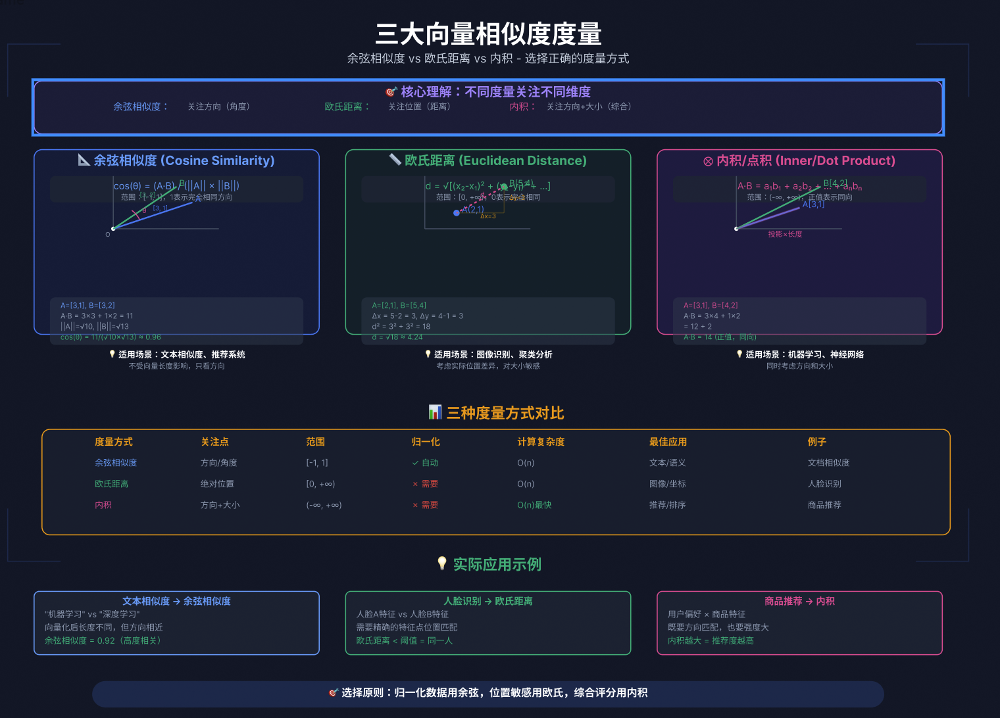

## 为什么快？

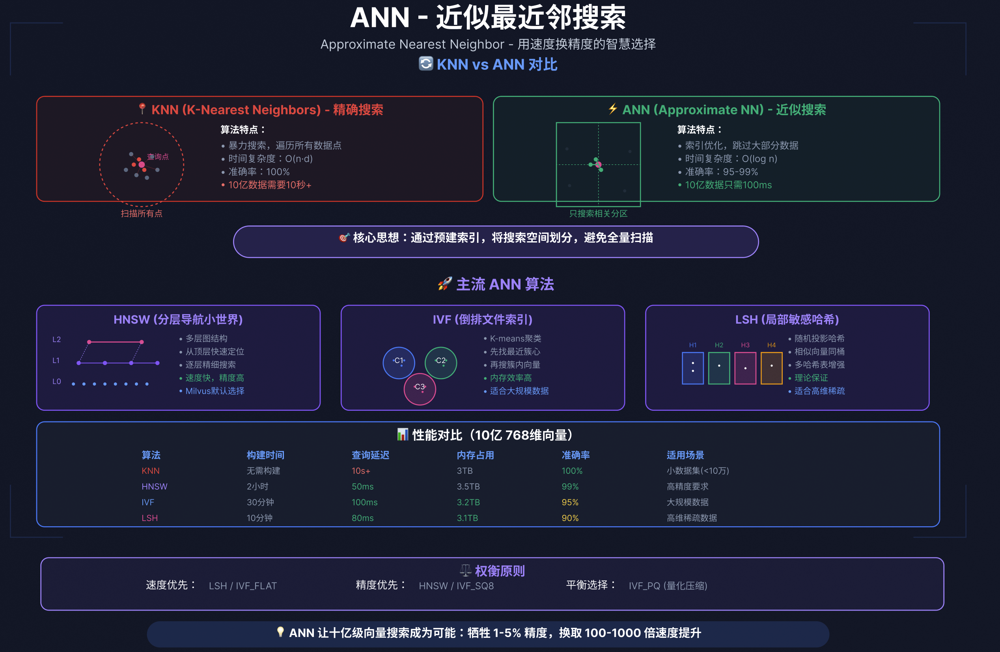

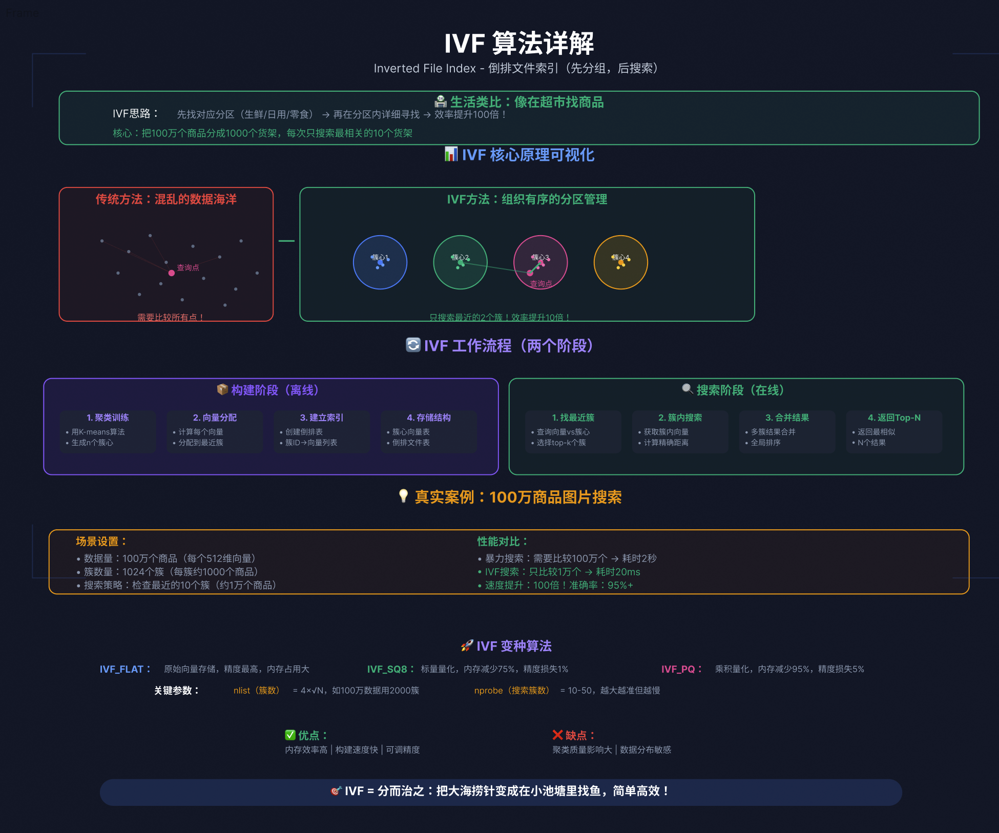

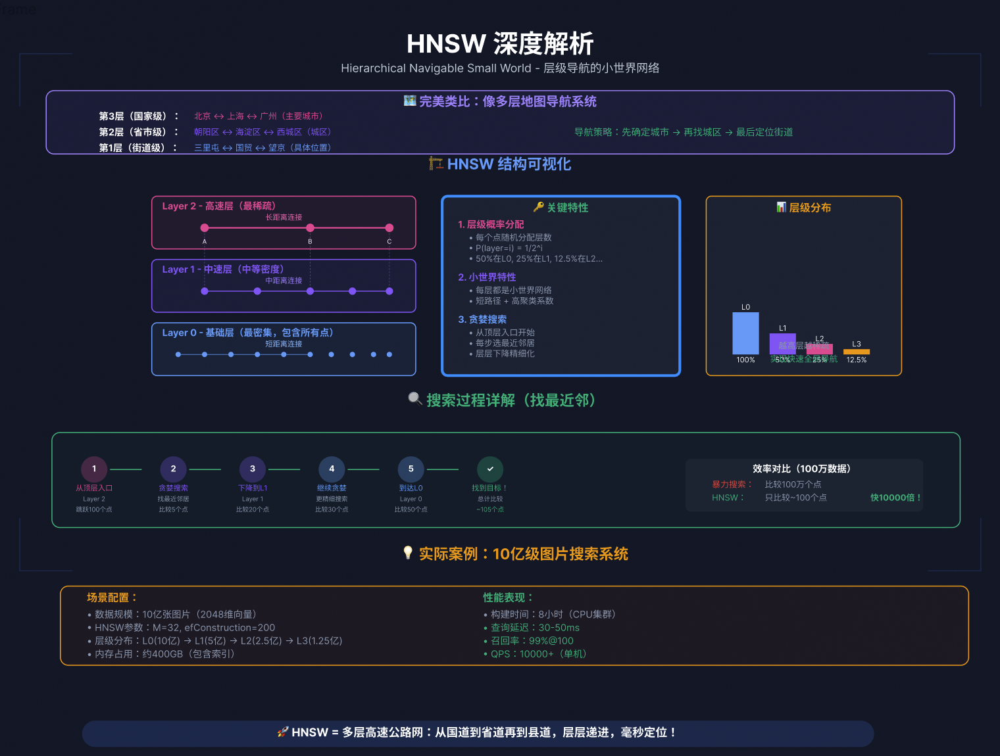

## 2.2 Milvus实战

### 2.2.1 离线文档入库

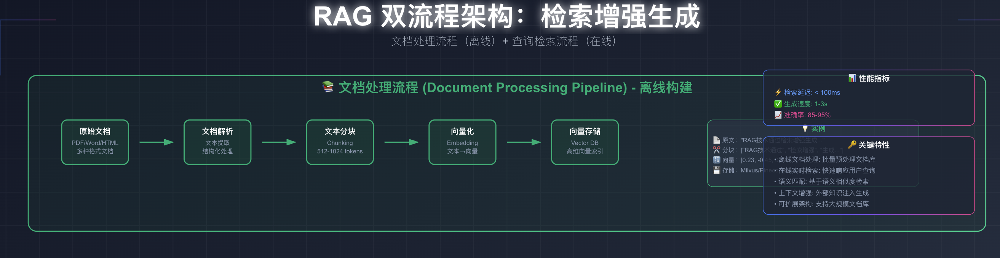

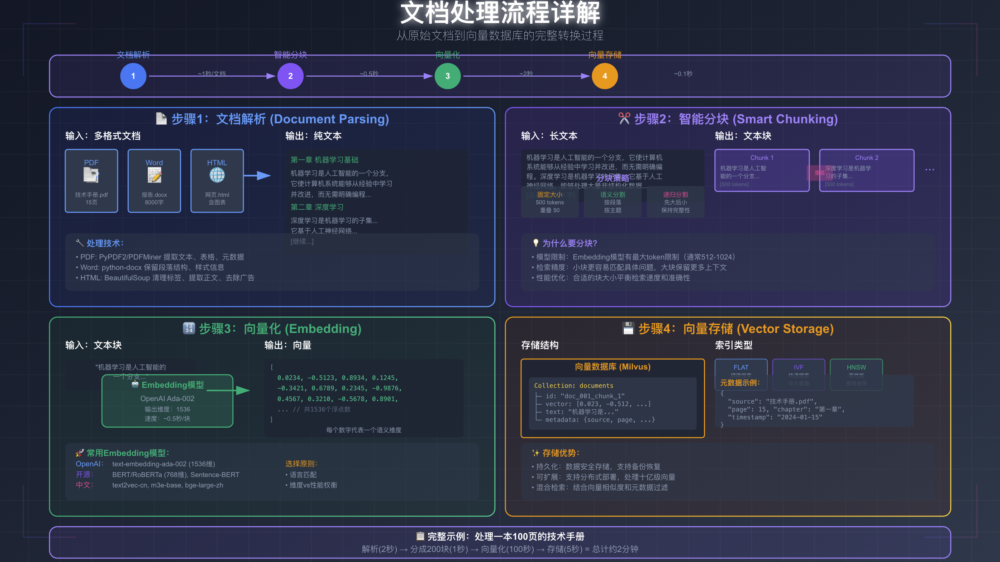

**具体的文档解析和分块（以及对应的优化策略）参考系统课第5周 and 第6周，务必好好看，都是面试考查点**
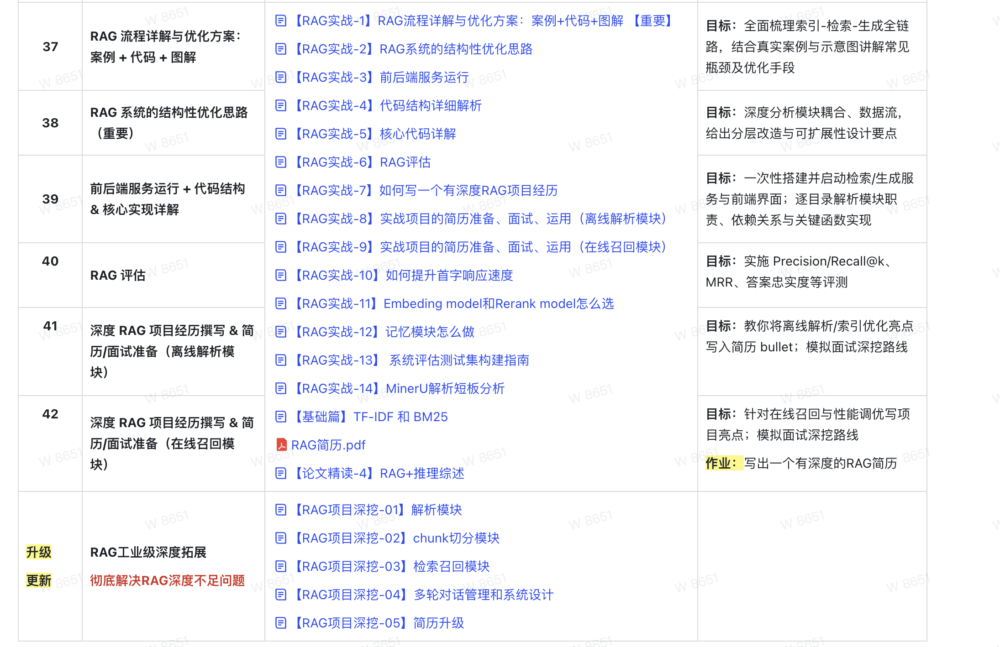
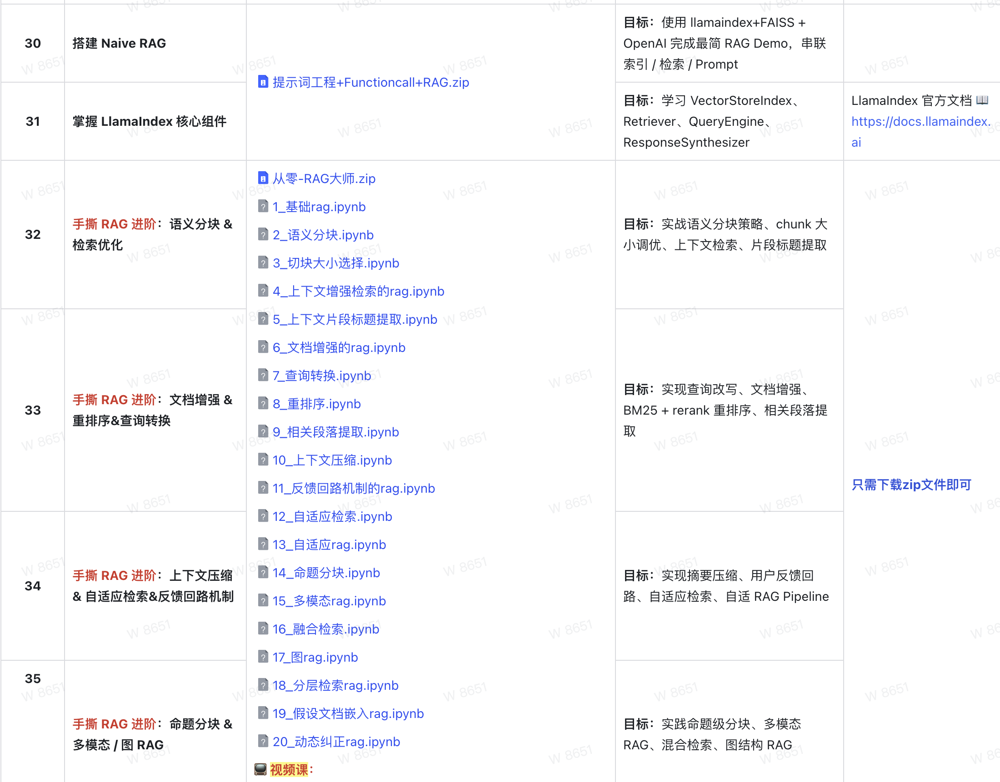

### 2.2.2 在线query查询

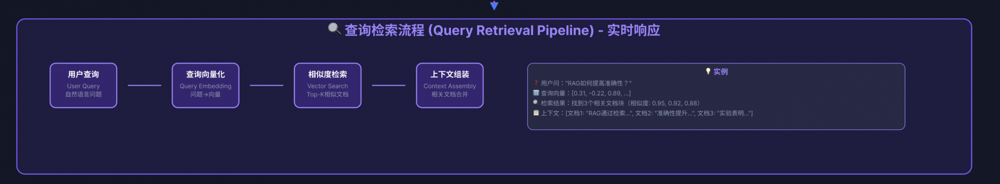

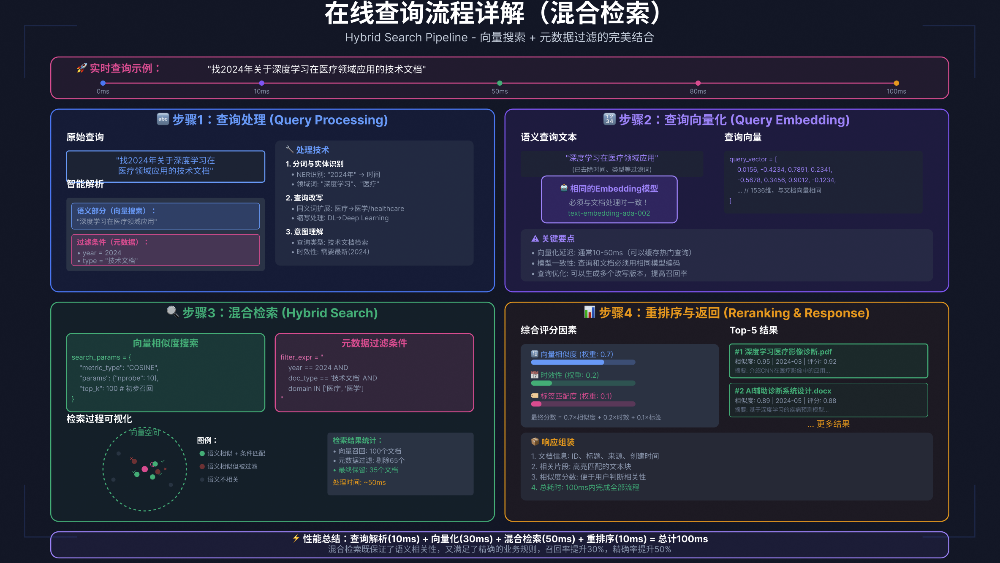

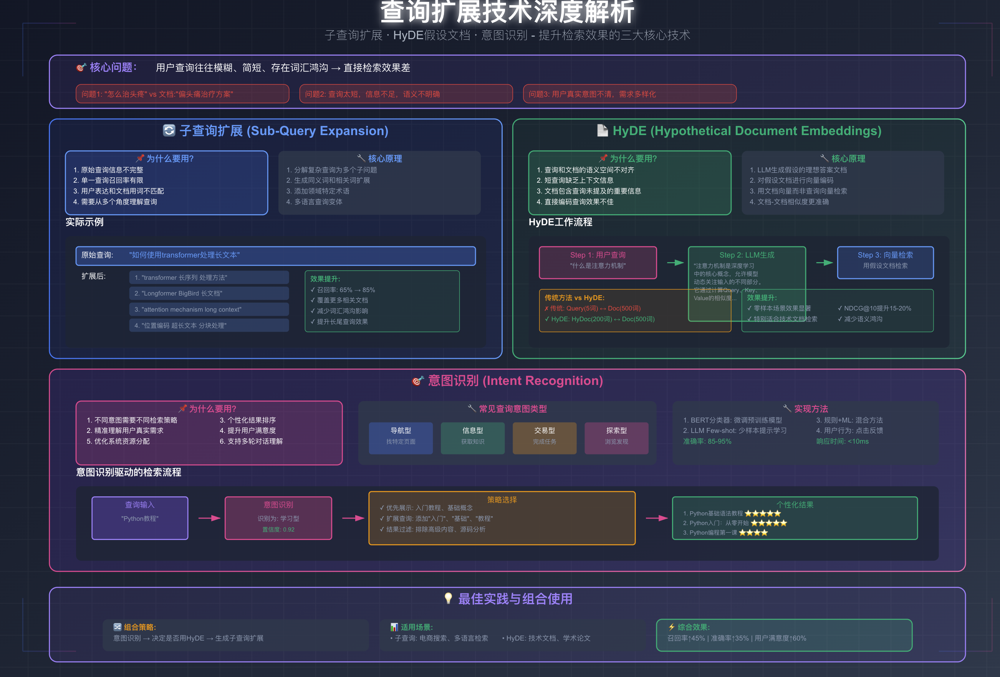

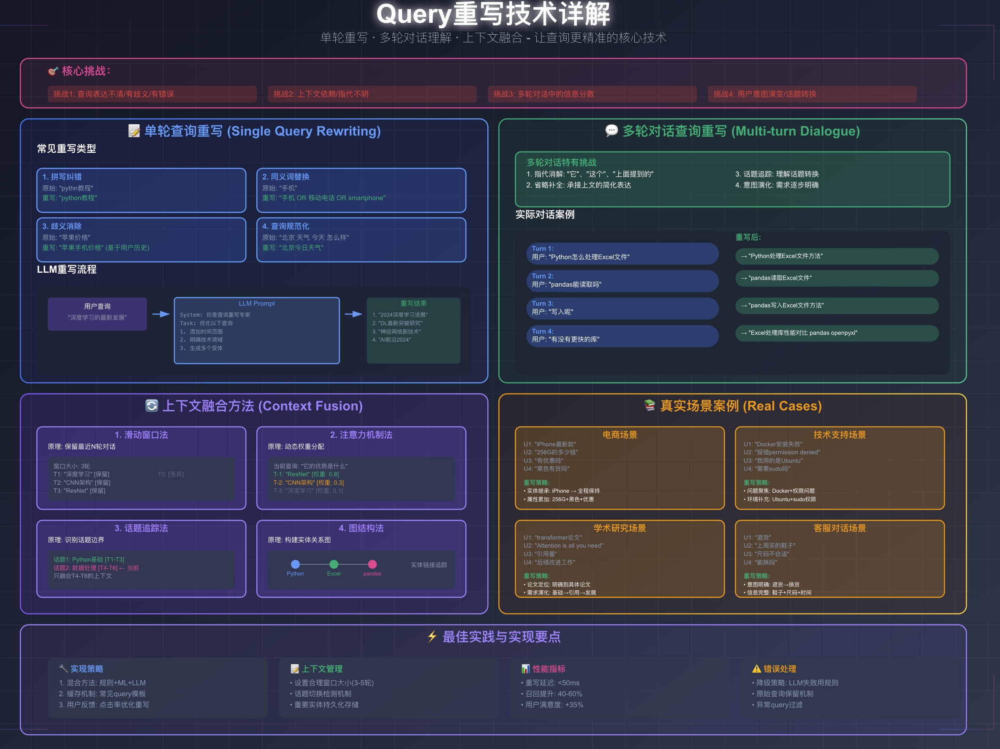

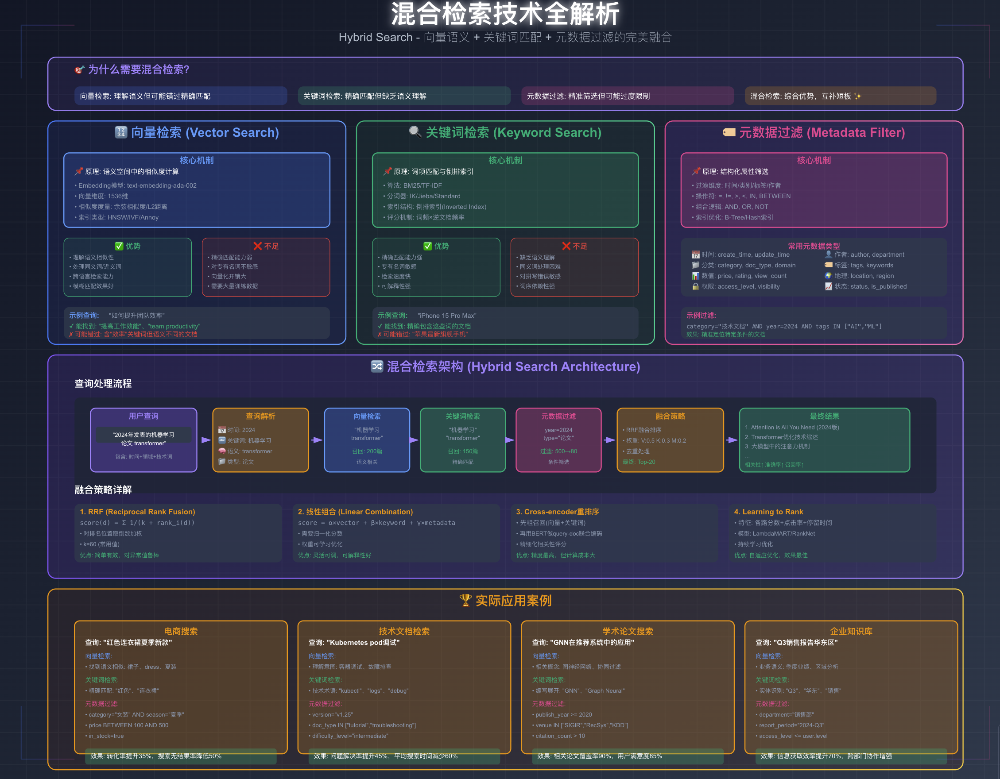

### 2.2.3 持久化服务

#### Restful API

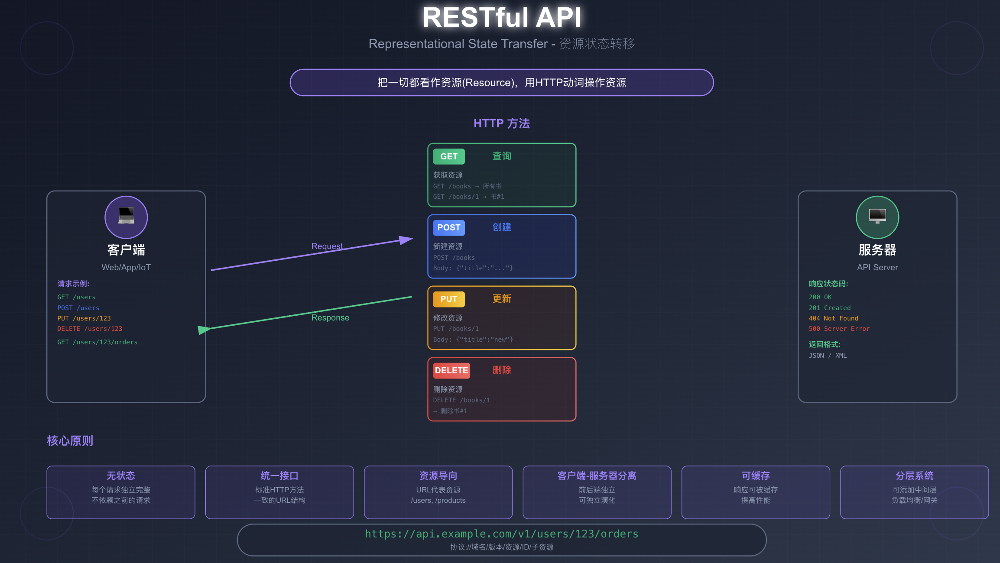

#### 微服务架构

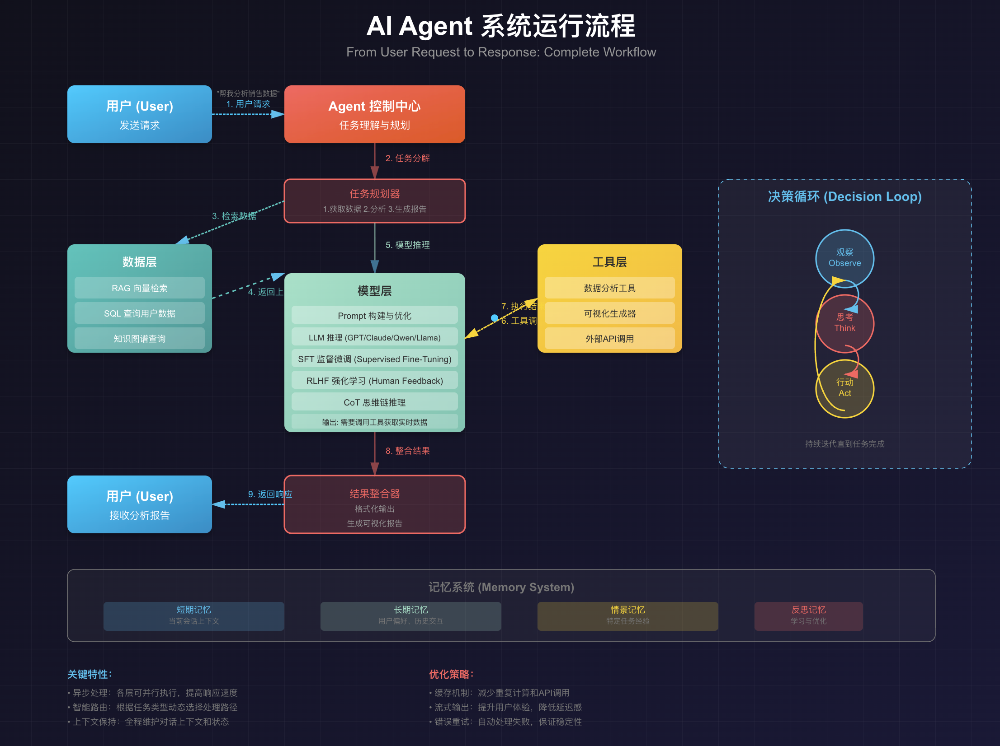

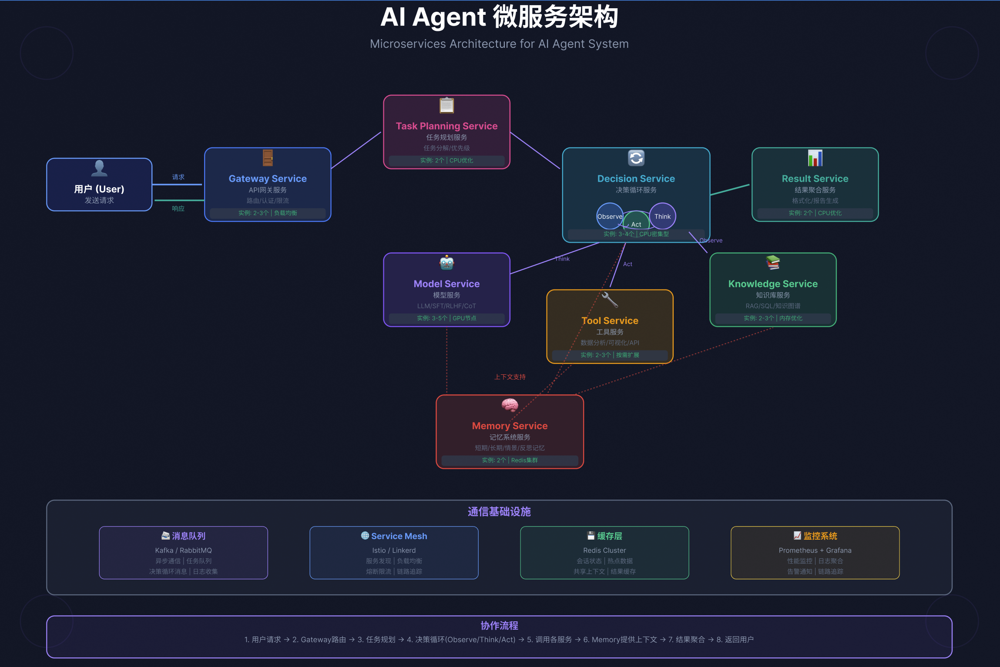

### 接下来，我们进入py脚本，开发一个包含了
1、router意图识别
2、query优化expansion
3、混合检索
4、元数据检索
5、答案引用 

的rag持久化服务

# RAG 服务架构

```
┌─────────────────────────────────────┐
│         用户应用层                   │
│  (Web/App/微信/钉钉等)              │
└────────────┬────────────────────────┘
             │ HTTP/WebSocket
┌────────────▼────────────────────────┐
│      RAG 业务服务层 ⭐               │
│   (rag_service.py)                  │
│  - 对话管理                         │
│  - 上下文维护                       │
│  - Prompt 优化                      │
│  - 结果重排序                       │
└────────────┬────────────────────────┘
             │ 调用 API
┌────────────▼────────────────────────┐
│    向量数据库 API 层                 │
│   (milvus_api.py) ✅ 已完成         │
│  - 向量检索                         │
│  - 数据管理                         │
└────────────┬────────────────────────┘
             │
┌────────────▼────────────────────────┐
│      Milvus 数据库                  │
└─────────────────────────────────────┘
```

## 架构说明

### 1. 用户应用层
- **功能**: 提供多渠道用户接入
- **支持平台**: Web、App、微信、钉钉等
- **通信协议**: HTTP/WebSocket

### 2. RAG 业务服务层 ⭐
- **文件**: `rag_service.py`
- **核心功能**:
  - 对话管理
  - 上下文维护
  - Prompt 优化
  - 结果重排序

### 3. 向量数据库 API 层
- **文件**: `milvus_api.py` 
- **状态**: ✅ 已完成
- **核心功能**:
  - 向量检索
  - 数据管理

### 4. Milvus 数据库
- **功能**: 底层向量存储与检索引擎

## 数据流向

1. 用户通过应用层发起请求
2. RAG 业务服务层处理业务逻辑
3. 调用向量数据库 API 进行检索
4. Milvus 执行向量搜索
5. 结果逐层返回至用户

# 微服务架构分析

## 🏗️ 当前架构分析

### ✅ 符合微服务特征的部分

#### 1. 服务拆分与独立部署

```
┌─────────────────┐     ┌─────────────────┐     ┌─────────────────┐
│   Milvus DB     │     │  Milvus API     │     │   RAG Service   │
│  (Port 19530)   │◄────│  (Port 8000)    │◄────│  (Port 8001/2)  │
└─────────────────┘     └─────────────────┘     └─────────────────┘
     Docker              Python Service         Python Service
```

#### 2. 单一职责原则

- **Milvus**: 向量存储与检索
- **Milvus API**: 数据 CRUD 操作
- **RAG Service**: 业务逻辑与 AI 处理
- **Attu**: 数据可视化

#### 3. 服务间通信

- HTTP REST API（8000, 8001, 8002）
- gRPC（19530）

#### 4. 技术栈独立

- **数据层**: Milvus + etcd + MinIO
- **API 层**: FastAPI + Python
- **业务层**: OpenAI API + Python

---

## ⚠️ 与标准微服务的差异

| 微服务标准特征 | 当前实现 | 改进建议 |
|------------|---------|---------|
| 服务发现 | ❌ 硬编码地址 | 添加 Consul/Eureka |
| API 网关 | ❌ 直接调用 | 添加 Kong/Nginx |
| 配置中心 | ⚠️ .env 文件 | 使用 Nacos/Apollo |
| 服务监控 | ❌ 基础日志 | 添加 Prometheus |
| 容器化 | ⚠️ 部分容器化 | 全部 Docker 化 |
| 负载均衡 | ❌ 单实例 | 添加负载均衡器 |
| 熔断器 | ❌ 无 | 添加 Hystrix |
| 分布式追踪 | ❌ 无 | 添加 Jaeger |

---

## 🎯 架构定位

**"轻量级微服务架构"** 或 **"模块化单体应用向微服务过渡"**

**架构成熟度**: ★★★☆☆

- 服务分离: ✅
- 独立部署: ✅
- API 通信: ✅
- 服务治理: ❌
- 高可用: ❌
